# Credit Risk Scorecard: from raw data to a credit score

**Goal:** estimate each borrower's **Probability of Default (PD)** over the next 2 years, then turn it into a
points-based **credit score** that a loan officer can read without knowing statistics.

**Default definition:** `SeriousDlqin2yrs = 1` means the borrower became **90+ days past due** within 2 years
(the same threshold banks use to classify a loan as non-performing).

**Why a scorecard and not just XGBoost?** Lenders must explain *why* someone was declined. A logistic regression on
binned variables gives every attribute a fixed number of points, so each decision can be traced and audited.
We benchmark a black-box model at the end to show how little accuracy that transparency costs.

**Roadmap:** load -> clean -> split -> bin and WoE/IV -> select variables -> logistic regression -> evaluate ->
scale to points -> stability (PSI) -> benchmark -> business cut-off.

> Re-run this notebook with `data/cs-training.csv` (Kaggle: *Give Me Some Credit*) to get the real numbers.
> The first output cell prints which file was used.

In [1]:
import sys, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, "..")
from src import data as D, metrics as M, scorecard as S
from src.binning import WoEBinner

pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.axisbelow": True, "figure.dpi": 100})
GOOD, BAD = "#2a78d6", "#eb6834"

DATA = "../data/cs-training.csv" if os.path.exists("../data/cs-training.csv") else "../data/synthetic_training.csv"
print("DATA SOURCE:", DATA, "<-- SYNTHETIC, for pipeline testing only" if "synthetic" in DATA else "")
raw = D.load_raw(DATA)
print("shape:", raw.shape)
raw.head()

DATA SOURCE: ../data/cs-training.csv 
shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. First look: default rate and class imbalance

Only a small share of borrowers default. A model that predicts "nobody defaults" would be ~93% accurate and
completely useless, which is why **accuracy is never the metric** here. We use **AUC, KS and Gini**, which measure
how well the model *ranks* risky borrowers above safe ones.

In [2]:
print("Default rate: %.2f%%" % (100 * raw[D.TARGET].mean()))
print("Accuracy of the useless 'nobody defaults' model: %.2f%%" % (100 * (1 - raw[D.TARGET].mean())))
print("\nMissing values (%):")
print((raw.isna().mean() * 100).round(2).to_string())
raw.describe().T[["min", "50%", "max"]]

Default rate: 6.68%
Accuracy of the useless 'nobody defaults' model: 93.32%

Missing values (%):
SeriousDlqin2yrs                         0.00
RevolvingUtilizationOfUnsecuredLines     0.00
age                                      0.00
NumberOfTime30-59DaysPastDueNotWorse     0.00
DebtRatio                                0.00
MonthlyIncome                           19.82
NumberOfOpenCreditLinesAndLoans          0.00
NumberOfTimes90DaysLate                  0.00
NumberRealEstateLoansOrLines             0.00
NumberOfTime60-89DaysPastDueNotWorse     0.00
NumberOfDependents                       2.62


,min,50%,max
SeriousDlqin2yrs,0.0,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,0.0,0.154181,50708.0
age,0.0,52.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,0.0,0.000000,98.0
DebtRatio,0.0,0.366508,329664.0
MonthlyIncome,0.0,5400.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,0.0,8.000000,58.0
NumberOfTimes90DaysLate,0.0,0.000000,98.0
NumberRealEstateLoansOrLines,0.0,1.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,0.0,0.000000,98.0


## 2. Data quality checks (the part interviewers love)

Look at the min/max columns above. Three things are suspicious:

1. **`age` = 0** is impossible, so those rows are invalid.
2. **Delinquency counts of 96 / 98** are not "96 times late"; they are placeholder / error codes.
3. **Utilisation far above 1** (ratio of balance to limit) and huge **DebtRatio** values are outliers.

Also, `MonthlyIncome` is missing for ~20% of borrowers. Missingness can itself carry risk, so we won't just fill it.

In [3]:
codes = D.DELINQ_COLS
print("Rows with age < 18:", int((raw["age"] < 18).sum()))
print("Rows with a 96/98 code:", int(raw[codes].isin(D.SPECIAL_CODES).any(axis=1).sum()))
sp = raw[codes].isin(D.SPECIAL_CODES).any(axis=1)
print("Default rate of those rows: %.1f%%  vs overall %.1f%%" % (100*raw.loc[sp, D.TARGET].mean(), 100*raw[D.TARGET].mean()))
print("Rows with utilisation > 1:", int((raw["RevolvingUtilizationOfUnsecuredLines"] > 1).sum()))
m = raw["MonthlyIncome"].isna()
print("\nDefault rate | income missing: %.2f%%   income present: %.2f%%" % (100*raw.loc[m, D.TARGET].mean(), 100*raw.loc[~m, D.TARGET].mean()))
print("Median DebtRatio | income missing: %.1f   income present: %.2f" % (raw.loc[m, "DebtRatio"].median(), raw.loc[~m, "DebtRatio"].median()))

Rows with age < 18: 1
Rows with a 96/98 code: 269
Default rate of those rows: 54.6%  vs overall 6.7%
Rows with utilisation > 1: 3321

Default rate | income missing: 5.61%   income present: 6.95%
Median DebtRatio | income missing: 1159.0   income present: 0.30


## 3. Clean, then split **before** any modelling

Cleaning rules (all logged): drop invalid ages; turn 96/98 into missing (so they get their own bin and keep their
high-risk signal); **do not cap outliers**, because binning puts extremes into the last bin where they can do no harm.

We split 70/30 (stratified) *before* binning. Bins, WoE and coefficients are learned from **train only**; fitting
them on all data would leak information from the test set into the model.

In [4]:
df, log = D.clean(raw)
print(log)
train, test = D.split(df)
features_all = [c for c in df.columns if c != D.TARGET]
ytr, yte = train[D.TARGET].to_numpy(), test[D.TARGET].to_numpy()
print("train", train.shape, "default rate %.3f" % ytr.mean(), "| test", test.shape, "default rate %.3f" % yte.mean())

{'rows_in': 150000, 'dropped_invalid_target_or_age': 1, 'delinquency_special_codes_set_to_nan': 807, 'rows_out': 149999, 'default_rate': 0.06684044560297069}
train (104999, 11) default rate 0.067 | test (45000, 11) default rate 0.067


## 4. Binning, Weight of Evidence (WoE) and Information Value (IV)

**Binning** groups each variable into a few ranges, found by a small decision tree and forced to be *monotonic*
(more utilisation never means less risk), with **Missing** as its own bin.

**Weight of Evidence** says how safe or risky a bin is:

`WoE = ln( % of all goods in the bin / % of all bads in the bin )`

* WoE > 0: the bin holds proportionally more good borrowers (safer). WoE < 0: riskier. WoE = 0: no information.

**Information Value** sums that up per variable: `IV = sum( (%good - %bad) * WoE )`.
Rule of thumb: < 0.02 useless, 0.02-0.1 weak, 0.1-0.3 medium, 0.3-0.5 strong, > 0.5 suspiciously good (check for leakage).

In [5]:
binner = WoEBinner(max_bins=6, min_bin_frac=0.02).fit(train[features_all], ytr)
iv = binner.iv_table()
iv

,feature,iv,strength
0,RevolvingUtilizationOfUnsecuredLines,1.116977,suspiciously strong
1,NumberOfTimes90DaysLate,0.851677,suspiciously strong
2,NumberOfTime30-59DaysPastDueNotWorse,0.738504,suspiciously strong
3,NumberOfTime60-89DaysPastDueNotWorse,0.576968,suspiciously strong
4,age,0.239125,medium
5,NumberOfOpenCreditLinesAndLoans,0.090926,weak
6,MonthlyIncome,0.065820,weak
7,NumberRealEstateLoansOrLines,0.038518,weak
8,NumberOfDependents,0.036010,weak
9,DebtRatio,0.019235,useless


In [6]:
col = iv.loc[0, "feature"]
t = binner.tables_[col]
print("Variable:", col)
t[["bin", "count", "pct", "goods", "bads", "bad_rate", "woe", "iv"]].round(4)

Variable: RevolvingUtilizationOfUnsecuredLines


,bin,count,pct,goods,bads,bad_rate,woe,iv
0,"(-inf, 0.3009]",64945,0.6185,63522,1423,0.0219,1.1624,0.5179
1,"(0.3009, 0.5003]",11141,0.1061,10494,647,0.0581,0.1496,0.0022
2,"(0.5003, 0.694]",7704,0.0734,6948,756,0.0981,-0.4183,0.0154
3,"(0.694, 0.8594]",5692,0.0542,4887,805,0.1414,-0.8329,0.0540
4,"(0.8594, 1.001]",13211,0.1258,10682,2529,0.1914,-1.1953,0.3003
5,"(1.001, inf)",2306,0.0220,1448,858,0.3721,-2.1128,0.2271


**One bin by hand**, so the formula is not a black box (riskiest bin of the variable above):

In [7]:
r = t.loc[t["woe"].idxmin()]
G, B = (ytr == 0).sum(), (ytr == 1).sum()
pg, pb = (r.goods + .5) / (G + .5 * len(t)), (r.bads + .5) / (B + .5 * len(t))
print(f"bin {r.bin}: goods={int(r.goods)}  bads={int(r.bads)}")
print(f"%good = {pg:.4f}   %bad = {pb:.4f}")
print(f"WoE = ln({pg:.4f} / {pb:.4f}) = {np.log(pg/pb):.4f}   (table says {r.woe:.4f})")
print("Negative WoE: this bin has far more of the bads than of the goods -> risky.")

bin (1.001, inf): goods=1448  bads=858
%good = 0.0148   %bad = 0.1223
WoE = ln(0.0148 / 0.1223) = -2.1128   (table says -2.1128)
Negative WoE: this bin has far more of the bads than of the goods -> risky.


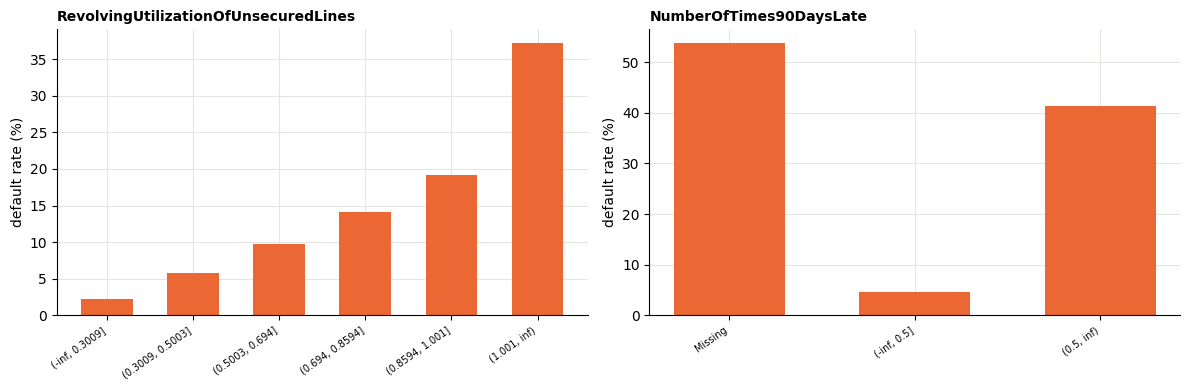

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, f in zip(axes, iv["feature"][:2]):
    tt = binner.tables_[f]
    ax.bar(range(len(tt)), tt["bad_rate"] * 100, color=BAD, width=.6)
    ax.set_xticks(range(len(tt))); ax.set_xticklabels(tt["bin"], rotation=35, ha="right", fontsize=7)
    ax.set_ylabel("default rate (%)"); ax.set_title(f[:42], loc="left", fontweight="bold", fontsize=10)
plt.tight_layout(); plt.show()

## 5. Variable selection

Keep variables with IV >= 0.02, then when two variables are highly correlated (|corr| > 0.75 on WoE) keep the one
with higher IV. The three delinquency counts are the usual culprits, because someone 90 days late was usually
30 days late first.

In [9]:
woe_tr = binner.transform(train[features_all])
woe_te = binner.transform(test[features_all])
cand, sel_log = S.select_features(iv, woe_tr)
print("\n".join(sel_log) or "nothing dropped")
print("\ncandidates:", cand)
woe_tr[cand].corr().round(2)

drop DebtRatio: IV < 0.02
WARNING RevolvingUtilizationOfUnsecuredLines: IV 1.12 > 0.5 (check for leakage)
WARNING NumberOfTimes90DaysLate: IV 0.85 > 0.5 (check for leakage)
WARNING NumberOfTime30-59DaysPastDueNotWorse: IV 0.74 > 0.5 (check for leakage)
WARNING NumberOfTime60-89DaysPastDueNotWorse: IV 0.58 > 0.5 (check for leakage)

candidates: ['RevolvingUtilizationOfUnsecuredLines', 'NumberOfTimes90DaysLate', 'NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'age', 'NumberOfOpenCreditLinesAndLoans', 'MonthlyIncome', 'NumberRealEstateLoansOrLines', 'NumberOfDependents']


,RevolvingUtilizationOfUnsecuredLines,NumberOfTimes90DaysLate,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,age,NumberOfOpenCreditLinesAndLoans,MonthlyIncome,NumberRealEstateLoansOrLines,NumberOfDependents
RevolvingUtilizationOfUnsecuredLines,1.00,0.29,0.27,0.23,0.25,0.26,0.11,0.12,0.09
NumberOfTimes90DaysLate,0.29,1.00,0.28,0.33,0.10,0.19,0.07,0.10,0.03
NumberOfTime30-59DaysPastDueNotWorse,0.27,0.28,1.00,0.32,0.10,-0.01,0.03,-0.01,0.07
NumberOfTime60-89DaysPastDueNotWorse,0.23,0.33,0.32,1.00,0.08,0.07,0.05,0.05,0.03
age,0.25,0.10,0.10,0.08,1.00,0.09,0.09,0.02,0.26
NumberOfOpenCreditLinesAndLoans,0.26,0.19,-0.01,0.07,0.09,1.00,0.10,0.35,-0.11
MonthlyIncome,0.11,0.07,0.03,0.05,0.09,0.10,1.00,0.22,-0.02
NumberRealEstateLoansOrLines,0.12,0.10,-0.01,0.05,0.02,0.35,0.22,1.00,-0.17
NumberOfDependents,0.09,0.03,0.07,0.03,0.26,-0.11,-0.02,-0.17,1.00


## 6. Logistic regression on WoE

We model `P(default)`. Because WoE is *higher = safer*, every coefficient must come out **negative**. A positive
coefficient is a red flag for multicollinearity, so the code drops that variable and refits.

Why logistic regression? It is a weighted sum of WoE values, hence fully explainable, stable, and accepted by regulators.

In [10]:
model, feats, sign_log = S.fit_logit(woe_tr, ytr, cand, binner.iv_)
print("\n".join(sign_log) or "all coefficient signs are negative, as expected")
coef = pd.DataFrame({"feature": feats, "coefficient": model.coef_[0]})
print("intercept:", round(float(model.intercept_[0]), 4))
coef

drop NumberRealEstateLoansOrLines: positive coefficient (sign flip from collinearity)
drop NumberOfOpenCreditLinesAndLoans: positive coefficient (sign flip from collinearity)
intercept: -2.5984


,feature,coefficient
0,RevolvingUtilizationOfUnsecuredLines,-0.635452
1,NumberOfTimes90DaysLate,-0.524811
2,NumberOfTime30-59DaysPastDueNotWorse,-0.505000
3,NumberOfTime60-89DaysPastDueNotWorse,-0.380697
4,age,-0.407716
5,MonthlyIncome,-0.397805
6,NumberOfDependents,-0.316019


## 7. Evaluation: AUC, KS, Gini

* **AUC**: probability a random bad is ranked riskier than a random good (0.5 = coin flip, 1 = perfect).
* **KS**: biggest gap between the cumulative share of bads and goods as you walk from riskiest to safest.
* **Gini** = 2 x AUC - 1 (the same information on a scale banks prefer).
* **Train vs test gap** tells us about overfitting.

          AUC      KS    Gini
train  0.8522  0.5475  0.7044
test   0.8526  0.5539  0.7052

Test AUC 95% bootstrap CI: 0.8455 to 0.8602


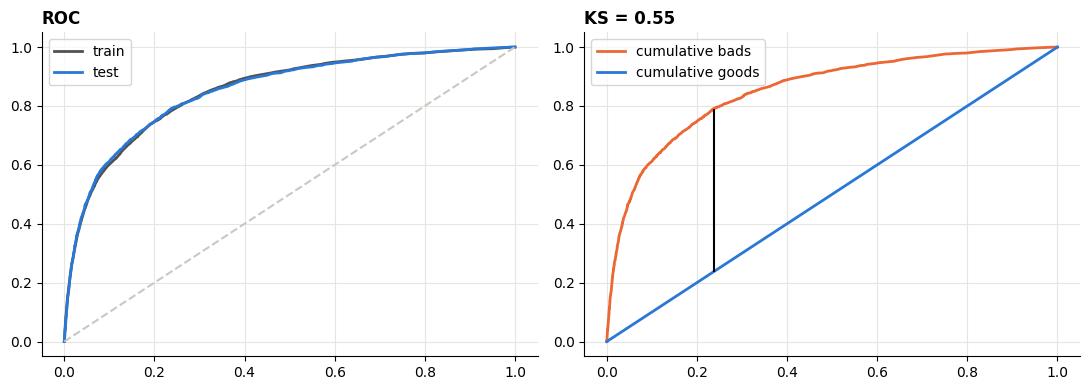

In [11]:
p_tr = model.predict_proba(woe_tr[feats])[:, 1]
p_te = model.predict_proba(woe_te[feats])[:, 1]
lo, hi = M.bootstrap_auc_ci(yte, p_te)
print(pd.DataFrame({"AUC": [M.auc(ytr, p_tr), M.auc(yte, p_te)],
                    "KS": [M.ks_stat(ytr, p_tr), M.ks_stat(yte, p_te)],
                    "Gini": [M.gini(ytr, p_tr), M.gini(yte, p_te)]}, index=["train", "test"]).round(4))
print(f"\nTest AUC 95% bootstrap CI: {lo:.4f} to {hi:.4f}")
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for (yy, pp), lab, c in (((ytr, p_tr), "train", "#52514e"), ((yte, p_te), "test", GOOD)):
    f_, t_, _ = roc_curve(yy, pp); ax[0].plot(f_, t_, color=c, lw=2, label=lab)
ax[0].plot([0, 1], [0, 1], "--", color="#c9c8c3"); ax[0].legend(); ax[0].set_title("ROC", loc="left", fontweight="bold")
f_, t_, _ = roc_curve(yte, p_te); k = np.argmax(t_ - f_)
ax[1].plot(f_, t_, color=BAD, lw=2, label="cumulative bads"); ax[1].plot(f_, f_, color=GOOD, lw=2, label="cumulative goods")
ax[1].vlines(f_[k], f_[k], t_[k], color="k"); ax[1].legend()
ax[1].set_title("KS = %.2f" % (t_[k] - f_[k]), loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 8. From probabilities to a credit score

Industry convention: **600 points at 50:1 good:bad odds, and every +20 points doubles the odds** (PDO = 20).

```
Factor = PDO / ln(2)            Offset = 600 - Factor * ln(50)
Score  = Offset + Factor * ln(odds_good)
```

Because the model is a sum of `coefficient x WoE`, the score splits cleanly into **points per bin**. The table
below *is* the scorecard.

In [12]:
sc = S.build_scorecard(binner, feats, model.coef_[0], float(model.intercept_[0]))
sc[["feature", "bin", "count", "bad_rate", "woe", "points"]].round(3)

,feature,bin,count,bad_rate,woe,points
0,RevolvingUtilizationOfUnsecuredLines,"(-inf, 0.3009]",64945,0.022,1.162,102
1,RevolvingUtilizationOfUnsecuredLines,"(0.3009, 0.5003]",11141,0.058,0.150,83
2,RevolvingUtilizationOfUnsecuredLines,"(0.5003, 0.694]",7704,0.098,-0.418,73
3,RevolvingUtilizationOfUnsecuredLines,"(0.694, 0.8594]",5692,0.141,-0.833,65
4,RevolvingUtilizationOfUnsecuredLines,"(0.8594, 1.001]",13211,0.191,-1.195,58
5,RevolvingUtilizationOfUnsecuredLines,"(1.001, inf)",2306,0.372,-2.113,42
6,NumberOfTimes90DaysLate,Missing,184,0.538,-2.788,38
7,NumberOfTimes90DaysLate,"(-inf, 0.5]",99093,0.046,0.396,86
8,NumberOfTimes90DaysLate,"(0.5, inf)",5722,0.413,-2.283,46
9,NumberOfTime30-59DaysPastDueNotWorse,Missing,184,0.538,-2.788,40


**Score one applicant by hand** (add up the points of each bin they fall in), then convert to a PD:

In [13]:
row = test.iloc[[0]]
total, detail = 0, []
for f in feats:
    bid = binner.assign(f, row[f])[0]
    pts = int(sc[(sc.feature == f) & (sc.bin_id == bid)]["points"].iloc[0])
    lab = sc[(sc.feature == f) & (sc.bin_id == bid)]["bin"].iloc[0]
    detail.append((f[:38], row[f].iloc[0], lab, pts)); total += pts
print(pd.DataFrame(detail, columns=["feature", "value", "bin", "points"]).to_string(index=False))
print("\nTOTAL SCORE:", total, "| implied PD: %.2f%%" % (100 * S.score_to_pd(total)),
      "| actual outcome:", int(row[D.TARGET].iloc[0]))

                             feature  value            bin  points
RevolvingUtilizationOfUnsecuredLines    0.0 (-inf, 0.3009]     102
             NumberOfTimes90DaysLate    1.0     (0.5, inf)      46
NumberOfTime30-59DaysPastDueNotWorse    0.0    (-inf, 0.5]      88
NumberOfTime60-89DaysPastDueNotWorse    1.0     (0.5, inf)      58
                                 age   50.0   (43.5, 55.5]      79
                       MonthlyIncome 9830.0    (5564, inf)      83
                  NumberOfDependents    0.0    (-inf, 0.5]      82

TOTAL SCORE: 538 | implied PD: 14.64% | actual outcome: 1


Test AUC using integer points only: 0.8523  (model: 0.8526)
Score range on test: 415.0 to 619.0


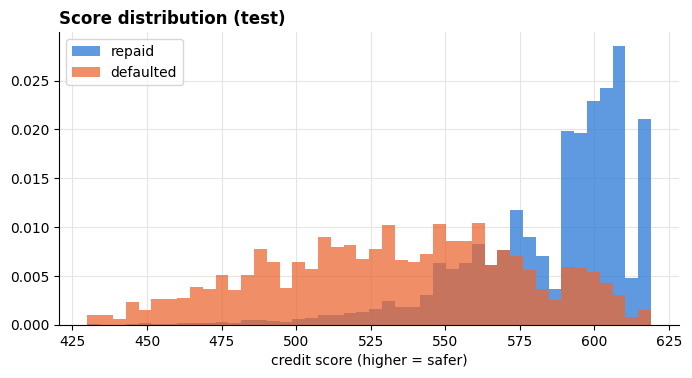

,band,n,min_score,max_score,bads,bad_rate,share_of_all_bads,cum_share_of_bads
0,1,4500,415.0,539.0,1635,0.3633,0.5436,0.5436
1,2,4500,539.0,558.0,486,0.1080,0.1616,0.7051
2,3,4500,558.0,572.0,313,0.0696,0.1041,0.8092
3,4,4500,572.0,583.0,180,0.0400,0.0598,0.8690
4,5,4500,583.0,593.0,128,0.0284,0.0426,0.9116
5,6,4500,593.0,598.0,85,0.0189,0.0283,0.9398
6,7,4500,598.0,602.0,71,0.0158,0.0236,0.9634
7,8,4500,602.0,608.0,53,0.0118,0.0176,0.9811
8,9,4500,608.0,612.0,30,0.0067,0.0100,0.9910
9,10,4500,612.0,619.0,27,0.0060,0.0090,1.0000


In [14]:
s_tr = S.apply_scorecard(sc, binner, train); s_te = S.apply_scorecard(sc, binner, test)
print("Test AUC using integer points only: %.4f  (model: %.4f)" % (M.auc(yte, -s_te), M.auc(yte, p_te)))
print("Score range on test:", s_te.min(), "to", s_te.max())
bins = np.linspace(np.quantile(s_te, .002), np.quantile(s_te, .998), 45)
plt.figure(figsize=(8, 3.8))
plt.hist(s_te[yte == 0], bins, color=GOOD, alpha=.75, density=True, label="repaid")
plt.hist(s_te[yte == 1], bins, color=BAD, alpha=.75, density=True, label="defaulted")
plt.legend(); plt.xlabel("credit score (higher = safer)"); plt.title("Score distribution (test)", loc="left", fontweight="bold")
plt.show()
M.score_band_table(yte, s_te).round(4)

## 9. Calibration and stability

* **Calibration:** do predicted PDs match reality? (Ranking well is not enough if the PD is used for pricing or provisions.)
* **PSI (Population Stability Index)** compares today's population to the one the model was built on.
  `< 0.10` stable, `0.10-0.25` investigate, `> 0.25` the population has shifted: re-validate the model.
  Here train vs test is a sanity check; in production you would compare each month against the development sample.

In [15]:
print(M.calibration_table(yte, S.score_to_pd(s_te)).round(4).to_string(index=False))
print("\nScore PSI (train vs test): %.5f" % M.psi_continuous(s_tr, s_te))
pd.Series({f: M.psi_binned(binner.assign(f, train[f]), binner.assign(f, test[f])) for f in feats}, name="PSI").round(5)

 bucket    n  mean_predicted_pd  observed_bad_rate
      1 4500             0.0114             0.0060
      2 4500             0.0143             0.0080
      3 4500             0.0170             0.0107
      4 4500             0.0198             0.0151
      5 4500             0.0226             0.0200
      6 4500             0.0280             0.0276
      7 4500             0.0427             0.0402
      8 4500             0.0629             0.0698
      9 4500             0.1016             0.1091
     10 4500             0.3486             0.3620

Score PSI (train vs test): 0.00028


RevolvingUtilizationOfUnsecuredLines    0.00035
NumberOfTimes90DaysLate                 0.00012
NumberOfTime30-59DaysPastDueNotWorse    0.00008
NumberOfTime60-89DaysPastDueNotWorse    0.00004
age                                     0.00007
MonthlyIncome                           0.00008
NumberOfDependents                      0.00007
Name: PSI, dtype: float64

## 10. Benchmark: how much accuracy does transparency cost?

Same train/test split, raw features, gradient boosting (XGBoost if installed, else scikit-learn's equivalent).

In [16]:
from src.train import get_benchmark_model
name, bm = get_benchmark_model()
bm.fit(train[features_all], ytr)
bm_auc = M.auc(yte, bm.predict_proba(test[features_all])[:, 1])
print(f"Scorecard test AUC : {M.auc(yte, p_te):.4f}\n{name} test AUC: {bm_auc:.4f}\ndifference: {bm_auc - M.auc(yte, p_te):+.4f}")

Scorecard test AUC : 0.8526
XGBoost test AUC: 0.8674
difference: +0.0148


## 11. The business view: choosing a cut-off

A score is only useful when it drives a decision. If we approve applicants at or above a cut-off, what share do we
approve, and how many defaults slip through?

In [17]:
cuts = np.round(np.quantile(s_te, [0, .1, .2, .3, .4, .5])).astype(int)
M.cutoff_table(yte, s_te, cuts).round(4)

,cutoff,approval_rate,bad_rate_among_approved,bads_caught_by_rejecting,overall_bad_rate
0,415,1.0000,0.0668,0.0000,0.0668
1,539,0.9009,0.0341,0.5402,0.0668
2,558,0.8058,0.0250,0.6988,0.0668
3,572,0.7038,0.0182,0.8078,0.0668
4,583,0.6022,0.0147,0.8677,0.0668
5,593,0.5104,0.0119,0.9092,0.0668


## 12. Limitations and what I would do next

* **Reject inference:** the data only contains approved borrowers; applicants who were rejected have no outcome, which biases any scorecard.
* **No out-of-time test:** one snapshot, so stability over time is untested. In production I would monitor PSI monthly and run a champion/challenger.
* **Fairness / regulation:** age is a strong predictor here; many jurisdictions restrict its use in lending decisions. A production model would need legal review.
* **Cost-sensitive cut-off:** choose the cut-off using real profit and loss per approved/declined loan, not just default rates.
* **Next:** add LGD and EAD to get Expected Loss = PD x LGD x EAD, and deploy the points table as an API or Streamlit app.